# MM HW 5 Q 2

## Part i

In [33]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt("lineardata-HW5.txt", delimiter="\t", skiprows=1)
t = data[:,0]
Y = data[:,1]
#print(t)
#print(Y)

The least-squares quantity is

$$
Q^2(\theta)
=
\sum_{i,j}
\left[Y_i-E[Y_i|\theta]\right]
V^{-1}_{ij}
\left[Y_j-E[Y_j|\theta]\right].
$$

Since the measurements are independent and identically distributed (iid) with
variance $\sigma^2$,

$$
V_{ij}=\sigma^2\delta_{ij},
$$

and therefore

$$
V^{-1}_{ij}=\frac{1}{\sigma^2}\delta_{ij}.
$$

So,

$$
Q^2(\theta)
=
\frac{1}{\sigma^2}
\sum_i
\left[Y_i-E[Y_i|\theta]\right]^2.
$$

Since

$$
E[Y_i|\theta_1,\theta_2]=\theta_1t_i+\theta_2,
$$

Subsitution

$$
Q^2(\theta_1,\theta_2)
=
\frac{1}{\sigma^2}
\sum_i
\left[Y_i-(\theta_1t_i+\theta_2)\right]^2.
$$

Because $\sigma^2$ is unknown but is a constant and independent of $\theta_1$
and $\theta_2$ then minimizing $Q^2$ is equivalent to minimizing

$$
Q^2\sigma^2
=
\sum_i
\left[Y_i-(\theta_1t_i+\theta_2)\right]^2.
$$

In [37]:
# Algorithm / brain
def Q2(theta1, theta2):
    Q = Y - (theta1 * t + theta2) 
    
    return np.sum(Q**2)

# What I want
optimized_theta1 = None
optimized_theta2 = None
optimized_QQ = np.inf

# The search for happiness
grid = np.linspace(-10, 10, 10000) # checking 1000 iid points in between -10 and 10 (so centered around 0)

for theta1 in grid:
    for theta2 in grid:
        current_QQ = Q2(theta1, theta2)

        if current_QQ < optimized_QQ:
            optimized_QQ = current_QQ
            optimized_theta1 = theta1
            optimized_theta2 = theta2


print(f"Best Theta 1: {optimized_theta1}\nBest Theta 2: {optimized_theta2}\nBest Q^2 ((Q*sigma)^2) Value: {optimized_QQ}")

Best Theta 1: 2.467246724672467
Best Theta 2: -3.0233023302330233
Best Q^2 ((Q*sigma)^2) Value: 46.368893403775935


## Part ii

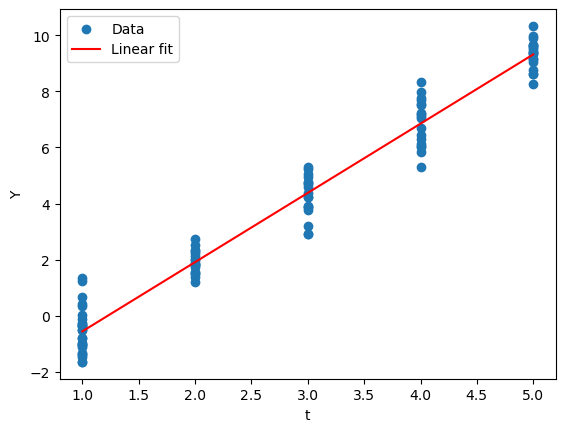

In [38]:
t_fit = np.linspace(min(t), max(t), 100)
Y_fit = optimized_theta1*t_fit + optimized_theta2

plt.scatter(t, Y, label="Data")
plt.plot(t_fit, Y_fit, label="Linear fit", c='r')

plt.xlabel("t")
plt.ylabel("Y")
plt.legend()
plt.show()

Original number of points: 100
Number of unique t values: 5
[1. 2. 3. 4. 5.]


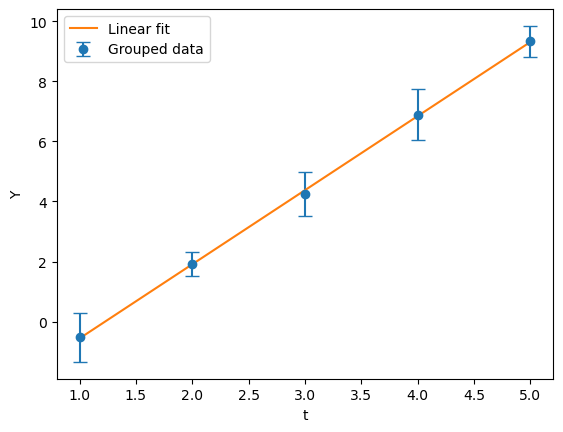

In [39]:
t_unique = np.unique(t) # ignore repeating values of t
print("Original number of points:", len(t))
print("Number of unique t values:", len(t_unique))
print(t_unique)

means = []
variances = []

for ti in t_unique:
    Yi = Y[t == ti] # This creates our groups asking Y to be Y of t if t = {chosen group, ti}
    
    means.append(np.mean(Yi))
    variances.append(np.var(Yi, ddof=1))


errors = np.sqrt(variances)

plt.errorbar(t_unique, means, yerr=errors,
             fmt='o', capsize=5, label="Grouped data")

plt.plot(t_fit, Y_fit, label="Linear fit")

plt.xlabel("t")
plt.ylabel("Y")
plt.legend()
plt.show()